# 01 — Data audit and descriptive baseline
Run this first. Edit `config.json` to point to your existing raw-data folder. This notebook preserves the original-file, fixed-cutoff baseline; it does not certify historical snapshot availability. Outputs are cleared intentionally.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.json").exists() and (p / "src" / "common.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the extracted project folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import paths, save_frame, load_frame
config, project_paths = paths(ROOT)
data_dir = project_paths["raw"]
processed_dir = project_paths["processed"]
figures_dir = project_paths["figures"]
tables_dir = project_paths["tables"]
artifacts_dir = project_paths["artifacts"]
cutoff = pd.Timestamp(config["cutoff"])


In [2]:
from src.data import build_base
base, audit = build_base(data_dir, config)
save_frame(base, processed_dir / 'subscriber_base.csv.gz')
(tables_dir / 'data_audit.json').write_text(json.dumps(audit, indent=2))
display(pd.Series(audit))
print('Overall label churn:', base.is_churn.mean())


raw_transaction_rows                        21547746
earliest_transaction             2015-01-01 00:00:00
latest_transaction               2017-02-28 00:00:00
invalid_transaction_dates                          0
latest_candidate_rows                         981847
latest_identical_rows_removed                    199
ambiguous_subscribers                          10944
labeled_subscribers                           970960
campaign_subscribers                          941518
missing_history                                 2527
post_cutoff_registration                        1057
dtype: object

Overall label churn: 0.08994191315811156


## Cohort and latest-state rules
Distinct same-day ties remain ambiguous; no arbitrary ordering. Raw transaction history retains duplicates. Campaign eligibility requires an unambiguous March expiry. Registration dates after cutoff are masked for tenure, but demographic snapshot timing remains unresolved.

In [3]:
base["campaign_eligible"] = (
    base["latest_membership_expire_date"]
    .between("2017-03-01", "2017-03-31")
    & ~base["latest_transaction_ambiguous"]
    & ~base["transaction_history_missing"]
)

print("Churn by provisional campaign eligibility:")
display(
    base.groupby("campaign_eligible")
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
)



Churn by provisional campaign eligibility:


,subscribers,churners,churn_rate
campaign_eligible,,,
False,29442,12318,0.418382
True,941518,75012,0.079671


In [4]:
campaign = base.loc[base["campaign_eligible"]].copy()

auto_renew_summary = (
    campaign.groupby("latest_is_auto_renew")
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
    .rename_axis("is_auto_renew")
)

display(
    auto_renew_summary.style.format({
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)

,subscribers,churners,churn_rate
is_auto_renew,,,
0.000000,"108,121","43,471",40.21%
1.000000,"833,397","31,541",3.78%


In [5]:
plan_renewal_summary = (
    campaign.groupby(
        ["latest_payment_plan_days", "latest_is_auto_renew"]
    )
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
    .sort_values("subscribers", ascending=False)
)

display(
    plan_renewal_summary.head(20).style.format({
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)


In [6]:
# Turn the grouped index back into ordinary columns.
plan_renewal_flat = plan_renewal_summary.reset_index()

display(
    plan_renewal_flat.loc[
        plan_renewal_flat["latest_payment_plan_days"].eq(30)
    ]
)

,latest_payment_plan_days,latest_is_auto_renew,subscribers,churners,churn_rate
0,30.0,1.0,833395,31539,0.037844
1,30.0,0.0,84771,24199,0.285463


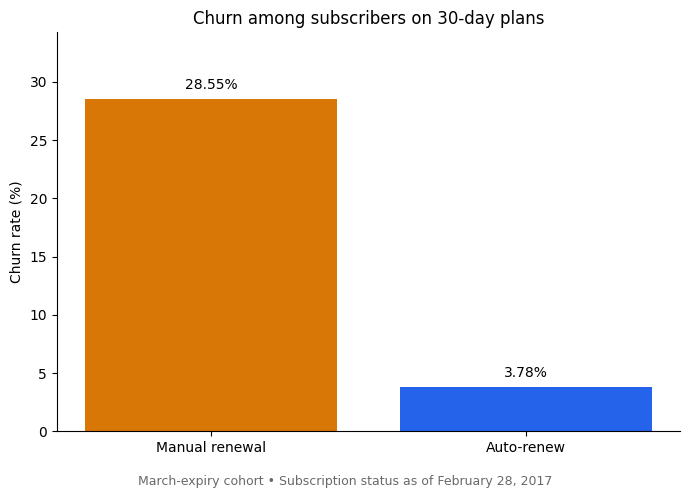

In [7]:
import matplotlib.pyplot as plt

plot_data = (
    plan_renewal_flat.loc[
        plan_renewal_flat["latest_payment_plan_days"].eq(30)
    ]
    .sort_values("latest_is_auto_renew")
)

labels = ["Manual renewal", "Auto-renew"]
rates = plot_data["churn_rate"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(labels, rates, color=["#D97706", "#2563EB"])

ax.bar_label(bars, labels=[f"{rate:.2f}%" for rate in rates], padding=5)
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn among subscribers on 30-day plans")
ax.set_ylim(0, rates.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "March-expiry cohort • Subscription status as of February 28, 2017",
    ha="center", fontsize=9, color="dimgray"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

figures_dir = project_paths["figures"]
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "churn_by_auto_renew_30_day.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
cancel_summary = (
    campaign.groupby(
        ["latest_is_auto_renew", "latest_is_cancel"]
    )
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
    .reset_index()
)

display(
    cancel_summary.style.format({
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)

,latest_is_auto_renew,latest_is_cancel,subscribers,churners,churn_rate
0,0.000000,0.000000,"108,121","43,471",40.21%
1,1.000000,0.000000,"830,016","29,148",3.51%
2,1.000000,1.000000,"3,381","2,393",70.78%


In [9]:
money_columns = [
    "latest_payment_plan_days",
    "latest_plan_list_price",
    "latest_actual_amount_paid"
]

display(
    campaign[money_columns].describe(
        percentiles=[0.01, 0.5, 0.95, 0.99]
    )
)

print("Zero or negative list prices:",
      campaign["latest_plan_list_price"].le(0).sum())

print("Zero or negative payments:",
      campaign["latest_actual_amount_paid"].le(0).sum())

print("Payments above list price:",
      campaign["latest_actual_amount_paid"]
      .gt(campaign["latest_plan_list_price"]).sum())

,latest_payment_plan_days,latest_plan_list_price,latest_actual_amount_paid
count,941518.000000,941518.000000,941518.000000
mean,35.290803,152.448566,152.107726
std,39.290044,170.745636,170.897542
min,0.000000,0.000000,0.000000
1%,30.000000,99.000000,99.000000
50%,30.000000,149.000000,149.000000
95%,30.000000,180.000000,180.000000
99%,195.000000,894.000000,894.000000
max,450.000000,2000.000000,2000.000000


Zero or negative list prices: 540
Zero or negative payments: 2490
Payments above list price: 3


In [10]:
# Calculate discount depth only where list price is positive.
valid_list_price = campaign["latest_plan_list_price"].where(
    campaign["latest_plan_list_price"].gt(0)
)

campaign["discount_depth"] = (
    1 - campaign["latest_actual_amount_paid"] / valid_list_price
)

# Flag exceptions without changing the original values.
campaign["payment_above_list"] = (
    campaign["latest_actual_amount_paid"]
    .gt(campaign["latest_plan_list_price"])
)

print("Payments above list price:")
display(
    campaign.loc[
        campaign["payment_above_list"],
        [
            "latest_payment_plan_days",
            "latest_plan_list_price",
            "latest_actual_amount_paid",
            "latest_is_cancel",
            "is_churn"
        ]
    ]
)

print("\nZero-payment records by plan length:")
display(
    campaign.loc[campaign["latest_actual_amount_paid"].eq(0)]
    .groupby("latest_payment_plan_days")
    .agg(
        subscribers=("msno", "size"),
        churn_rate=("is_churn", "mean")
    )
)

Payments above list price:


,latest_payment_plan_days,latest_plan_list_price,latest_actual_amount_paid,latest_is_cancel,is_churn
row_id,,,,,
24290,0.0,0.0,149.0,0.0,1
607895,0.0,0.0,1788.0,0.0,1
610945,410.0,1788.0,1799.0,0.0,1



Zero-payment records by plan length:


,subscribers,churn_rate
latest_payment_plan_days,,
1.0,88,0.772727
7.0,178,0.764045
10.0,44,0.909091
30.0,1956,0.375767
60.0,65,0.738462
90.0,33,0.878788
120.0,20,0.900000
180.0,28,0.928571
195.0,7,0.857143


In [11]:
import numpy as np

discount = campaign["discount_depth"]

campaign["discount_band"] = pd.cut(
    discount,
    bins=[-np.inf, 0, 0.10, 0.25, 0.50, 1],
    labels=[
        "No discount",
        "Up to 10%",
        "10–25%",
        "25–50%",
        "50–100%"
    ],
    include_lowest=True
).astype("string")

# Separate exceptions from valid discounts.
campaign.loc[
    campaign["latest_plan_list_price"].le(0),
    "discount_band"
] = "Unknown: zero list price"

campaign.loc[
    campaign["payment_above_list"],
    "discount_band"
] = "Payment above list"

campaign.loc[
    discount.eq(1),
    "discount_band"
] = "100%: zero payment"

discount_summary = (
    campaign.groupby("discount_band", dropna=False)
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
    .sort_values("subscribers", ascending=False)
)

display(
    discount_summary.style.format({
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)

,subscribers,churners,churn_rate
discount_band,,,
No discount,"938,335","73,816",7.87%
100%: zero payment,"1,952",730,37.40%
Unknown: zero list price,538,446,82.90%
25–50%,445,6,1.35%
10–25%,244,11,4.51%
Payment above list,3,3,100.00%
Up to 10%,1,0,0.00%


In [12]:
# Zero-day plans cannot support a per-day revenue calculation.
valid_plan_days = campaign["latest_payment_plan_days"].where(
    campaign["latest_payment_plan_days"].gt(0)
)

campaign["revenue_30d_proxy"] = (
    campaign["latest_actual_amount_paid"] / valid_plan_days * 30
)

payment = campaign["latest_actual_amount_paid"]
revenue_30d = campaign["revenue_30d_proxy"]

payment_weighted_churn = (
    (payment * campaign["is_churn"]).sum() / payment.sum()
)

revenue_30d_weighted_churn = (
    (revenue_30d * campaign["is_churn"]).sum() / revenue_30d.sum()
)

print(f"Subscriber churn: {campaign['is_churn'].mean():.2%}")
print(f"Latest-payment weighted churn: {payment_weighted_churn:.2%}")
print(f"30-day-equivalent weighted churn: {revenue_30d_weighted_churn:.2%}")
print(
    "Subscribers excluded from the 30-day calculation:",
    f"{revenue_30d.isna().sum():,}"
)

Subscriber churn: 7.97%
Latest-payment weighted churn: 19.86%
30-day-equivalent weighted churn: 8.59%
Subscribers excluded from the 30-day calculation: 2


In [13]:
campaign["churned_revenue_30d_proxy"] = (
    campaign["revenue_30d_proxy"] * campaign["is_churn"]
)

revenue_summary = (
    campaign.groupby("latest_is_auto_renew")
    .agg(
        subscribers=("msno", "size"),
        known_revenue_subscribers=("revenue_30d_proxy", "count"),
        revenue_30d_proxy=("revenue_30d_proxy", "sum"),
        churned_revenue_30d_proxy=("churned_revenue_30d_proxy", "sum")
    )
)

revenue_summary["revenue_weighted_churn"] = (
    revenue_summary["churned_revenue_30d_proxy"]
    / revenue_summary["revenue_30d_proxy"]
)

revenue_summary["share_of_churned_value"] = (
    revenue_summary["churned_revenue_30d_proxy"]
    / revenue_summary["churned_revenue_30d_proxy"].sum()
)

display(revenue_summary.round(4))

,subscribers,known_revenue_subscribers,revenue_30d_proxy,churned_revenue_30d_proxy,revenue_weighted_churn,share_of_churned_value
latest_is_auto_renew,,,,,,
0.0,108121,108120,1.656720e+07,6.289950e+06,0.3797,0.5996
1.0,833397,833396,1.055111e+08,4.200112e+06,0.0398,0.4004


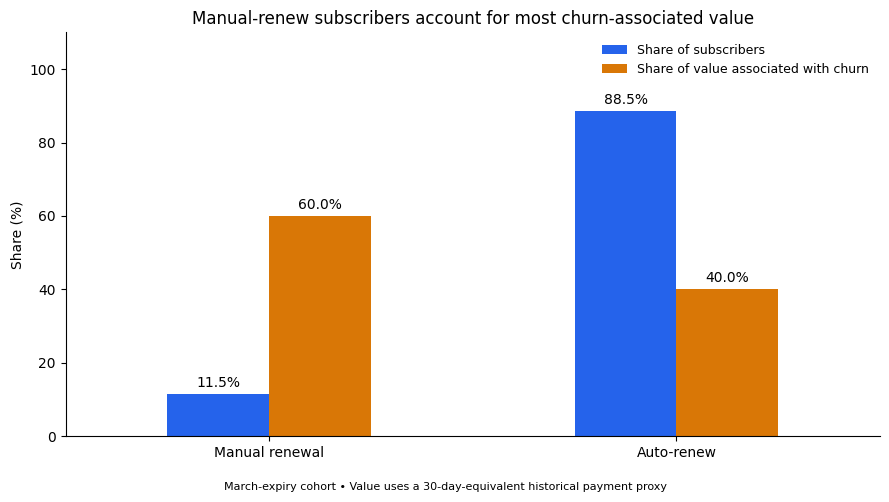

In [14]:
shares = pd.DataFrame({
    "Share of subscribers": (
        revenue_summary["subscribers"]
        / revenue_summary["subscribers"].sum()
    ),
    "Share of value associated with churn": (
        revenue_summary["share_of_churned_value"]
    )
})

shares.index = shares.index.map({0: "Manual renewal", 1: "Auto-renew"})

ax = (shares * 100).plot.bar(
    figsize=(9, 5),
    color=["#2563EB", "#D97706"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Manual-renew subscribers account for most churn-associated value")
ax.set_ylabel("Share (%)")
ax.set_xlabel("")
ax.set_ylim(0, 110)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

fig = ax.get_figure()
fig.text(
    0.5, 0.01,
    "March-expiry cohort • Value uses a 30-day-equivalent historical payment proxy",
    ha="center", fontsize=8
)
fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    figures_dir / "manual_renew_churn_value_concentration.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [15]:
payment_summary = (
    campaign.groupby("latest_payment_method_id")
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean"),
        auto_renew_share=("latest_is_auto_renew", "mean")
    )
    .sort_values("subscribers", ascending=False)
    .reset_index()
)

display(
    payment_summary.style.format({
        "latest_payment_method_id": "{:.0f}",
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}",
        "auto_renew_share": "{:.2%}"
    })
)

,latest_payment_method_id,subscribers,churners,churn_rate,auto_renew_share
0,41,"532,694","15,716",2.95%,100.00%
1,40,"71,437","4,708",6.59%,100.00%
2,36,"69,234","9,352",13.51%,64.46%
3,39,"66,567","4,156",6.24%,100.00%
4,38,"58,327","21,231",36.40%,0.00%
5,37,"34,518","1,081",3.13%,100.00%
6,34,"28,760",554,1.93%,99.99%
7,29,"17,820","3,598",20.19%,45.40%
8,30,"14,504","1,499",10.34%,100.00%
9,33,"14,120",500,3.54%,99.86%


In [16]:
comparison = campaign.loc[
    campaign["latest_payment_method_id"].isin([36, 29])
    & campaign["latest_payment_plan_days"].eq(30)
]

within_method_summary = (
    comparison.groupby([
        "latest_payment_method_id",
        "latest_is_auto_renew"
    ])
    .agg(
        subscribers=("msno", "size"),
        churners=("is_churn", "sum"),
        churn_rate=("is_churn", "mean")
    )
    .reset_index()
)

display(
    within_method_summary.style.format({
        "latest_payment_method_id": "{:.0f}",
        "latest_is_auto_renew": "{:.0f}",
        "subscribers": "{:,.0f}",
        "churners": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)

,latest_payment_method_id,latest_is_auto_renew,subscribers,churners,churn_rate
0,29,0,"8,650","2,324",26.87%
1,29,1,"8,090",667,8.24%
2,36,0,"24,608","7,099",28.85%
3,36,1,"44,626","2,253",5.05%


The association between manual renewal and higher churn persists within 30-day plans using the same payment method. Manual-renew churn was 26.87% versus 8.24% for method 29, and 28.85% versus 5.05% for method 36. This supports testing retention interventions among manual-renew subscribers, but does not establish the effect of converting them to auto-renew.

In [17]:
campaign["tenure_band"] = pd.cut(
    campaign["tenure_days"],
    bins=[0, 90, 365, 730, np.inf],
    labels=["0–90 days", "91–365 days", "1–2 years", "Over 2 years"],
    include_lowest=True
).astype("string").fillna("Unknown")

tenure_summary = (
    campaign.groupby("tenure_band", dropna=False)
    .agg(
        subscribers=("msno", "size"),
        churn_rate=("is_churn", "mean"),
        auto_renew_share=("latest_is_auto_renew", "mean")
    )
    .reset_index()
)

display(
    tenure_summary.style.format({
        "subscribers": "{:,.0f}",
        "churn_rate": "{:.2%}",
        "auto_renew_share": "{:.2%}"
    })
)

,tenure_band,subscribers,churn_rate,auto_renew_share
0,0–90 days,"46,993",9.04%,83.79%
1,1–2 years,"181,037",7.86%,86.06%
2,91–365 days,"131,156",7.44%,87.10%
3,Over 2 years,"475,009",9.00%,87.75%
4,Unknown,"107,323",3.77%,99.86%


Registration tenure shows no simple monotonic relationship with churn. Among subscribers with known tenure, churn ranges from 7.44% to 9.04%. Subscribers with unknown tenure have lower churn but are almost exclusively on auto-renew, highlighting differences in segment composition.

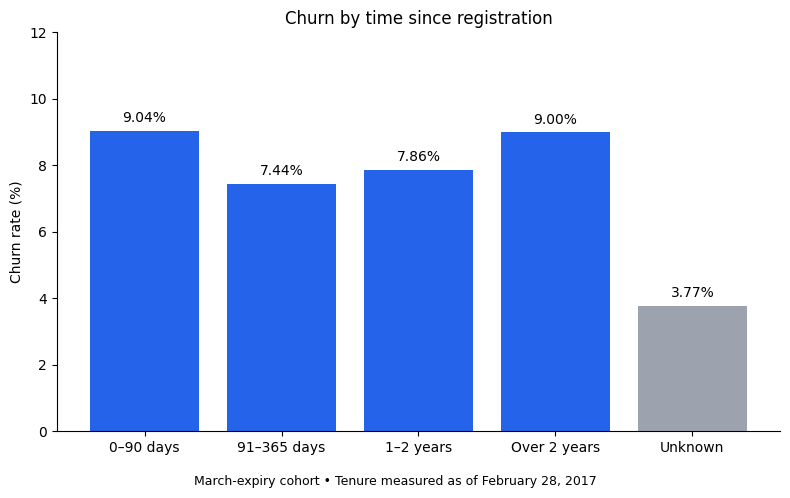

In [18]:
tenure_order = [
    "0–90 days", "91–365 days", "1–2 years",
    "Over 2 years", "Unknown"
]

plot_data = tenure_summary.set_index("tenure_band").reindex(tenure_order)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data["churn_rate"] * 100,
    color=["#2563EB"] * 4 + ["#9CA3AF"]
)

ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set_title("Churn by time since registration")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 12)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "March-expiry cohort • Tenure measured as of February 28, 2017",
    ha="center", fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(
    figures_dir / "churn_by_registration_tenure.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [19]:
for column in ["city", "registered_via"]:
    summary = (
        campaign.groupby(column, dropna=False)
        .agg(
            subscribers=("msno", "size"),
            churn_rate=("is_churn", "mean"),
            auto_renew_share=("latest_is_auto_renew", "mean")
        )
        .sort_values("subscribers", ascending=False)
        .head(10)
        .reset_index()
    )

    print(f"\nChurn by {column}:")
    display(
        summary.style.format({
            "subscribers": "{:,.0f}",
            "churn_rate": "{:.2%}",
            "auto_renew_share": "{:.2%}"
        })
    )


Churn by city:


,city,subscribers,churn_rate,auto_renew_share
0,1.000000,"429,766",5.19%,92.40%
1,nan,"107,318",3.77%,99.86%
2,13.000000,"93,842",11.76%,82.62%
3,5.000000,"68,332",12.51%,80.33%
4,4.000000,"45,441",12.15%,81.36%
5,15.000000,"41,945",12.19%,81.60%
6,22.000000,"40,535",11.90%,81.12%
7,6.000000,"25,194",12.26%,80.02%
8,14.000000,"19,401",11.03%,84.82%
9,12.000000,"10,965",13.09%,78.40%



Churn by registered_via:


,registered_via,subscribers,churn_rate,auto_renew_share
0,7.000000,"450,098",3.31%,99.25%
1,9.000000,"228,470",12.12%,80.50%
2,nan,"107,318",3.77%,99.86%
3,3.000000,"102,492",16.64%,65.44%
4,4.000000,"50,224",22.11%,50.96%
5,13.000000,"2,916",7.37%,99.86%


In [20]:
for name in ['auto_renew_summary', 'plan_renewal_summary', 'cancel_summary', 'discount_summary', 'revenue_summary', 'payment_summary', 'within_method_summary', 'tenure_summary']:
    globals()[name].to_csv(tables_dir / f'{name}.csv')
save_frame(campaign.drop(columns=['churned_revenue_30d_proxy'], errors='ignore'), processed_dir / 'campaign_eda_checkpoint.csv.gz')
print('Next: run 02_features.ipynb in its own kernel.')

Next: run 02_features.ipynb in its own kernel.


In [1]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path("/Users/iangaffney/Desktop/Internship!/KKbox")
config = json.loads((ROOT / "config.json").read_text())

raw_dir = Path(config["raw_data_dir"]).expanduser()
if not raw_dir.is_absolute():
    raw_dir = ROOT / raw_dir

# Historical v2 rows identified by the previous audit.
v2_extra = pd.read_csv(
    ROOT / "Data/processed/v2_pre_cutoff_rows_absent_from_original.csv.gz"
)

keys = ["msno", "transaction_date"]
candidate_dates = pd.MultiIndex.from_frame(v2_extra[keys])
subscriber_ids = set(v2_extra["msno"])
matched_dates = set()
rows_scanned = 0

# Read only subscriber IDs and dates to keep memory use low.
for chunk in pd.read_csv(
    raw_dir / "transactions.csv",
    usecols=keys,
    chunksize=500_000,
):
    relevant = chunk.loc[chunk["msno"].isin(subscriber_ids), keys]

    matched_dates.update(
        candidate_dates.intersection(
            pd.MultiIndex.from_frame(relevant)
        ).tolist()
    )

    rows_scanned += len(chunk)
    if rows_scanned % 5_000_000 == 0:
        print(f"Scanned {rows_scanned:,} original rows...")

same_date = pd.Series(
    [key in matched_dates for key in candidate_dates],
    index=v2_extra.index,
)

summary = pd.DataFrame({
    "category": [
        "Same subscriber/date exists in original",
        "Subscriber/date absent from original",
    ],
    "v2_rows": [
        int(same_date.sum()),
        int((~same_date).sum()),
    ],
    "subscribers": [
        v2_extra.loc[same_date, "msno"].nunique(),
        v2_extra.loc[~same_date, "msno"].nunique(),
    ],
})

print("\nDiagnostic results:")
print(summary.to_string(index=False))
print("\nA subscriber can appear in both categories.")

Scanned 5,000,000 original rows...
Scanned 10,000,000 original rows...
Scanned 15,000,000 original rows...
Scanned 20,000,000 original rows...

Diagnostic results:
                               category  v2_rows  subscribers
Same subscriber/date exists in original     6251         3783
   Subscriber/date absent from original   163881        90043

A subscriber can appear in both categories.


In [2]:
# Uses v2_extra, same_date, raw_dir, and keys from the previous cell.
same_day_v2 = v2_extra.loc[same_date].copy()

fields = [
    "payment_method_id",
    "payment_plan_days",
    "plan_list_price",
    "actual_amount_paid",
    "is_auto_renew",
    "membership_expire_date",
    "is_cancel",
]

comparisons = []
same_day_ids = set(same_day_v2["msno"])

for chunk in pd.read_csv(
    raw_dir / "transactions.csv",
    usecols=keys + fields,
    chunksize=500_000,
):
    relevant = chunk.loc[chunk["msno"].isin(same_day_ids)]

    paired = same_day_v2.merge(
        relevant,
        on=keys,
        how="inner",
        suffixes=("_v2", "_original"),
    )

    if not paired.empty:
        comparisons.append(paired)

pairs = pd.concat(comparisons, ignore_index=True).drop_duplicates()

differences = pd.DataFrame({
    field: pairs[f"{field}_v2"].ne(pairs[f"{field}_original"])
    for field in fields
})

print(f"Distinct same-day row comparisons: {len(pairs):,}")

print("\nFields that differ:")
print(
    differences.sum()
    .sort_values(ascending=False)
    .rename("comparisons_with_difference")
    .to_string()
)

# Show examples without subscriber identifiers.
example_columns = ["transaction_date"]
for field in fields:
    example_columns.extend([f"{field}_original", f"{field}_v2"])

display(pairs[example_columns].head(10))

Distinct same-day row comparisons: 38,172

Fields that differ:
membership_expire_date    38172
actual_amount_paid          978
plan_list_price             915
is_cancel                   381
is_auto_renew               369
payment_method_id           330
payment_plan_days           275


,transaction_date,payment_method_id_original,payment_method_id_v2,payment_plan_days_original,payment_plan_days_v2,plan_list_price_original,plan_list_price_v2,actual_amount_paid_original,actual_amount_paid_v2,is_auto_renew_original,is_auto_renew_v2,membership_expire_date_original,membership_expire_date_v2,is_cancel_original,is_cancel_v2
0,20160720,38,38,7,7,0,0,0,0,0,0,20160803,20170524,0,0
1,20160720,38,38,7,7,0,0,0,0,0,0,20160803,20170816,0,0
2,20161028,38,38,7,7,0,0,0,0,0,0,20170319,20170402,0,0
3,20160720,38,38,7,7,0,0,0,0,0,0,20160803,20171213,0,0
4,20160720,38,38,7,7,0,0,0,0,0,0,20161117,20170720,0,0
5,20160724,38,38,7,7,0,0,0,0,0,0,20170212,20170730,0,0
6,20160721,38,38,7,7,0,0,0,0,0,0,20170126,20170406,0,0
7,20160807,38,38,7,7,0,0,0,0,0,0,20161217,20171230,0,0
8,20160720,38,38,7,7,0,0,0,0,0,0,20160803,20180214,0,0
9,20160415,38,38,7,7,35,35,35,35,0,0,20160707,20170525,0,0
